## import libraries and functions and row

In [43]:
%load_ext autoreload
%autoreload 2
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.append("..")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

from src.extraction import load_row, save_processed

df = load_row()

df

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
49995,0.72,Ideal,D,SI1,60.80,57.00,2757,5.75,5.76,3.50
49996,0.72,Good,D,SI1,63.10,55.00,2757,5.69,5.75,3.61
49997,0.70,Very Good,D,SI1,62.80,60.00,2757,5.66,5.68,3.56
49998,0.86,Premium,H,SI2,61.00,58.00,2757,6.15,6.12,3.74


## data description

In [34]:
display(df.head())
print(df.shape)
print(df.info())
display(df.describe())
print(df.dtypes)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


(50000, 10)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  str    
 2   color    50000 non-null  str    
 3   clarity  50000 non-null  str    
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.3 MB
None


,carat,depth,table,price,x,y,z
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,0.80,61.75,57.46,3944.81,5.73,5.74,3.54
std,0.48,1.43,2.23,3997.94,1.12,1.15,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,951.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2410.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5351.00,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
price        int64
x          float64
y          float64
z          float64
dtype: object


## Numerical and Categories variables 

In [35]:
numerical_df = df.select_dtypes(include=['number'])
categorical_df = df.select_dtypes(include=['category', 'object'])

display(numerical_df.head())
display(categorical_df.head())

C:\Users\lenovo pc\AppData\Local\Temp\ipykernel_4184\585684911.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_df = df.select_dtypes(include=['category', 'object'])


,carat,depth,table,price,x,y,z
0,0.23,61.50,55.00,326,3.95,3.98,2.43
1,0.21,59.80,61.00,326,3.89,3.84,2.31
2,0.23,56.90,65.00,327,4.05,4.07,2.31
3,0.29,62.40,58.00,334,4.20,4.23,2.63
4,0.31,63.30,58.00,335,4.34,4.35,2.75


,cut,color,clarity
0,Ideal,E,SI2
1,Premium,E,SI1
2,Good,E,VS1
3,Premium,I,VS2
4,Good,J,SI2


## missing, duplicates and inconsistencies values

In [44]:
# missing values
print(df.isna().sum())
# there is no missing value

# duplicate
print("\n", df.duplicated().sum())
# i need to drop duplicates

df = df.drop_duplicates()

print("\n", df.duplicated().sum())

# inconsistencies
for col in ['cut', 'color', 'clarity']:
    print(f"\n{col}: ")
    print(df[col].unique())

# x, y, z drop invalid values
display(df[df['x'] <= 0])
display(df[df['y'] <= 0])
display(df[df['z'] <= 0])

df = df.drop(df[df['x'] <= 0].index)
df = df.drop(df[df['y'] <= 0].index)
df = df.drop(df[df['z'] <= 0].index)

df.shape

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

 126

 0

cut: 
<ArrowStringArray>
['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Length: 5, dtype: str

color: 
<ArrowStringArray>
['E', 'I', 'J', 'H', 'F', 'G', 'D']
Length: 7, dtype: str

clarity: 
<ArrowStringArray>
['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Length: 8, dtype: str


,carat,cut,color,clarity,depth,table,price,x,y,z
10310,1.07,Ideal,F,SI2,61.60,56.00,4954,0.00,6.62,0.00
11038,1.00,Very Good,H,VS2,63.30,53.00,5139,0.00,0.00,0.00
14731,1.14,Fair,G,VS1,57.50,67.00,6381,0.00,0.00,0.00
22721,1.56,Ideal,G,VS2,62.20,54.00,12800,0.00,0.00,0.00
24336,1.20,Premium,D,VVS1,62.10,59.00,15686,0.00,0.00,0.00
25439,2.25,Premium,H,SI2,62.80,59.00,18034,0.00,0.00,0.00
45910,0.71,Good,F,SI2,64.10,60.00,2130,0.00,0.00,0.00


,carat,cut,color,clarity,depth,table,price,x,y,z
11038,1.00,Very Good,H,VS2,63.30,53.00,5139,0.00,0.00,0.00
14731,1.14,Fair,G,VS1,57.50,67.00,6381,0.00,0.00,0.00
22721,1.56,Ideal,G,VS2,62.20,54.00,12800,0.00,0.00,0.00
24336,1.20,Premium,D,VVS1,62.10,59.00,15686,0.00,0.00,0.00
25439,2.25,Premium,H,SI2,62.80,59.00,18034,0.00,0.00,0.00
45910,0.71,Good,F,SI2,64.10,60.00,2130,0.00,0.00,0.00


,carat,cut,color,clarity,depth,table,price,x,y,z
2046,1.00,Premium,G,SI2,59.10,59.00,3142,6.55,6.48,0.00
4422,1.10,Premium,G,SI2,63.00,59.00,3696,6.50,6.47,0.00
5038,1.01,Premium,F,SI2,59.20,58.00,3837,6.50,6.47,0.00
9370,1.50,Good,G,I1,64.00,61.00,4731,7.15,7.04,0.00
10310,1.07,Ideal,F,SI2,61.60,56.00,4954,0.00,6.62,0.00
11038,1.00,Very Good,H,VS2,63.30,53.00,5139,0.00,0.00,0.00
12568,1.15,Ideal,G,VS2,59.20,56.00,5564,6.88,6.83,0.00
14731,1.14,Fair,G,VS1,57.50,67.00,6381,0.00,0.00,0.00
22598,2.18,Premium,H,SI2,59.40,61.00,12631,8.49,8.45,0.00
22721,1.56,Ideal,G,VS2,62.20,54.00,12800,0.00,0.00,0.00


(49857, 10)

## distributions of variables using histograms and boxplots.

In [37]:
print(df["cut"].value_counts())
print()
print(df["color"].value_counts())
print()
print(df["clarity"].value_counts())

cut
Ideal        19878
Premium      12760
Very Good    11193
Good          4544
Fair          1482
Name: count, dtype: int64

color
G    10416
E     9067
F     8841
H     7679
D     6208
I     5044
J     2602
Name: count, dtype: int64

clarity
SI1     12085
VS2     11374
SI2      8475
VS1      7563
VVS2     4687
VVS1     3362
IF       1626
I1        685
Name: count, dtype: int64


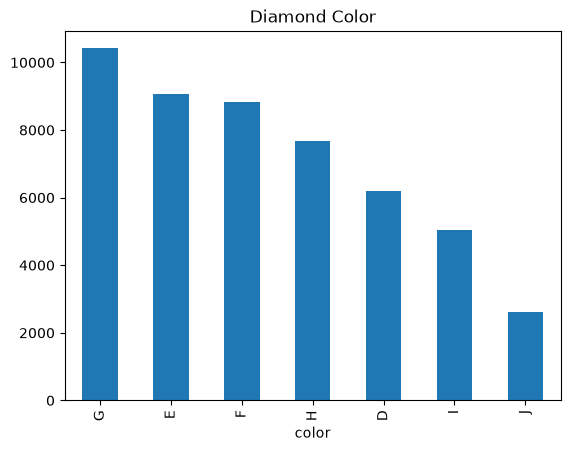

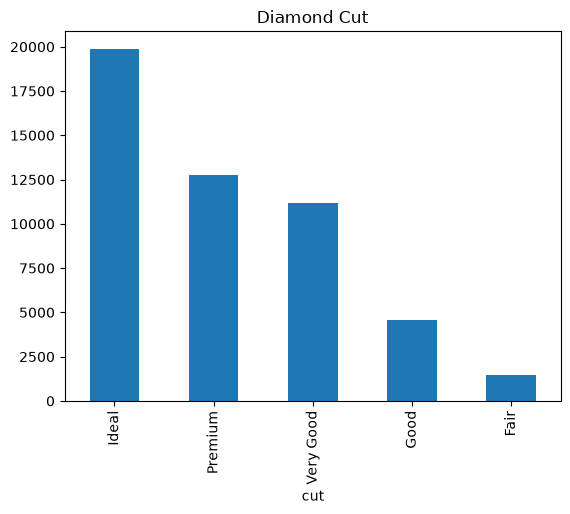

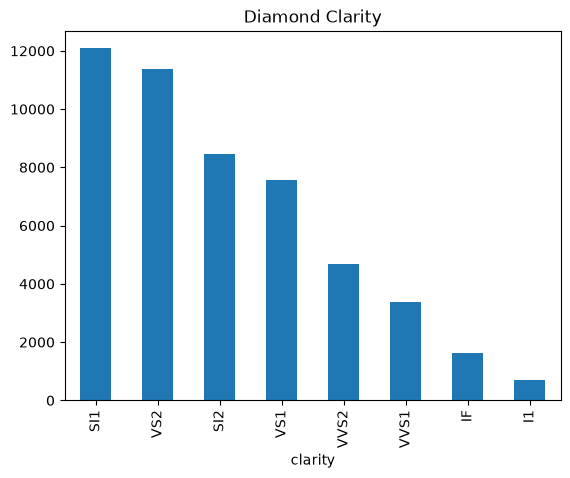

In [38]:
df["color"].value_counts().plot(kind="bar", title="Diamond Color")
plt.show()

df["cut"].value_counts().plot(kind="bar", title="Diamond Cut")
plt.show()

df["clarity"].value_counts().plot(kind="bar", title="Diamond Clarity")
plt.show()

IQR = 0.64 | Q1 = 0.4 | Q3 = 1.04 | lower = -0.5599999999999999 | upper = 2.0


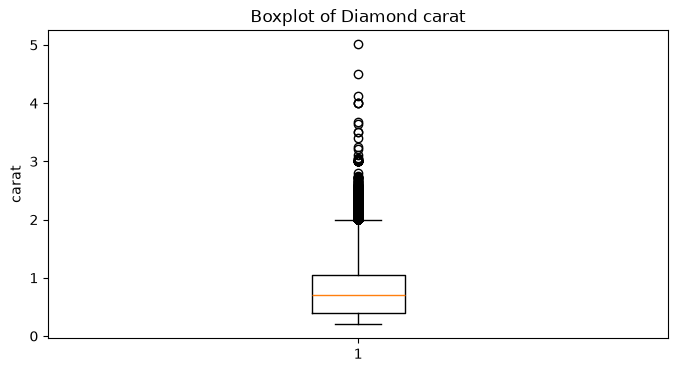

IQR = 1.5 | Q1 = 61.0 | Q3 = 62.5 | lower = 58.75 | upper = 64.75


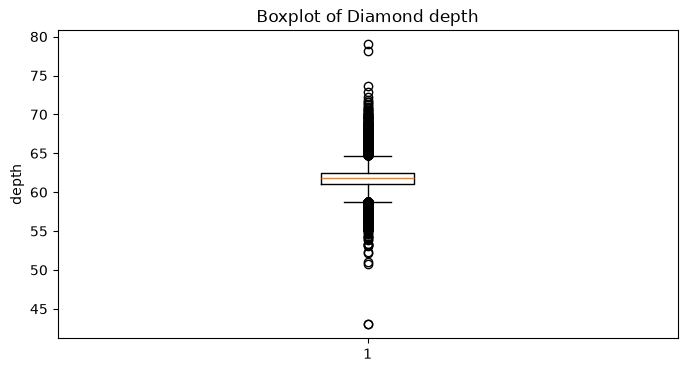

IQR = 3.0 | Q1 = 56.0 | Q3 = 59.0 | lower = 51.5 | upper = 63.5


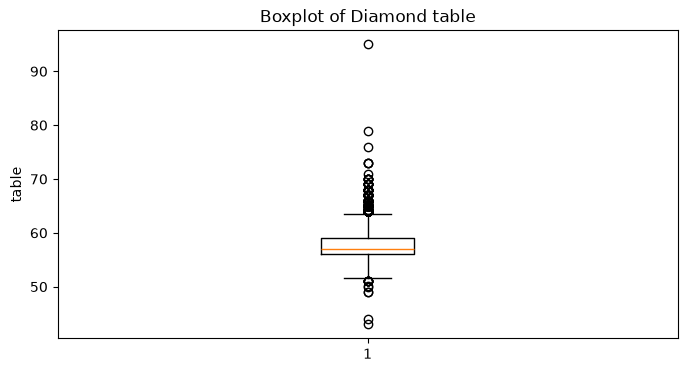

IQR = 4399.0 | Q1 = 952.0 | Q3 = 5351.0 | lower = -5646.5 | upper = 11949.5


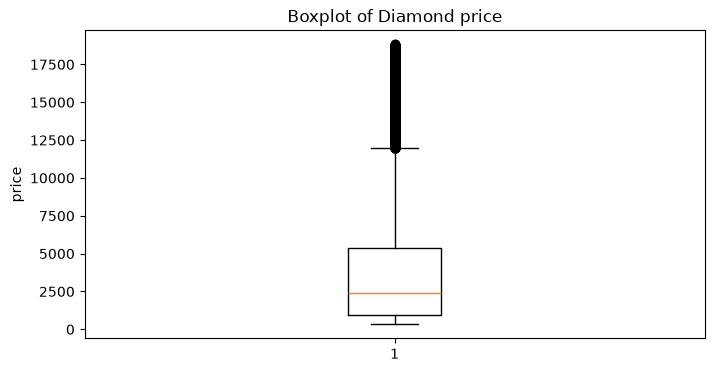

IQR = 1.8200000000000003 | Q1 = 4.72 | Q3 = 6.54 | lower = 1.9899999999999993 | upper = 9.27


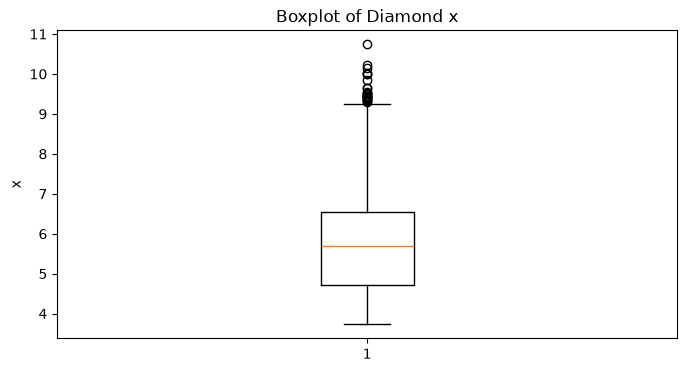

IQR = 1.8200000000000003 | Q1 = 4.72 | Q3 = 6.54 | lower = 1.9899999999999993 | upper = 9.27


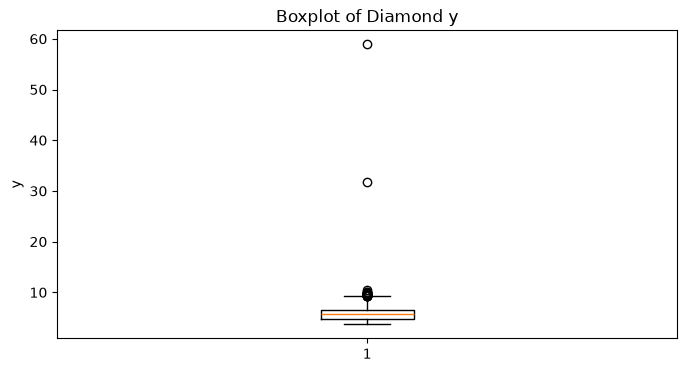

IQR = 1.13 | Q1 = 2.91 | Q3 = 4.04 | lower = 1.2150000000000003 | upper = 5.734999999999999


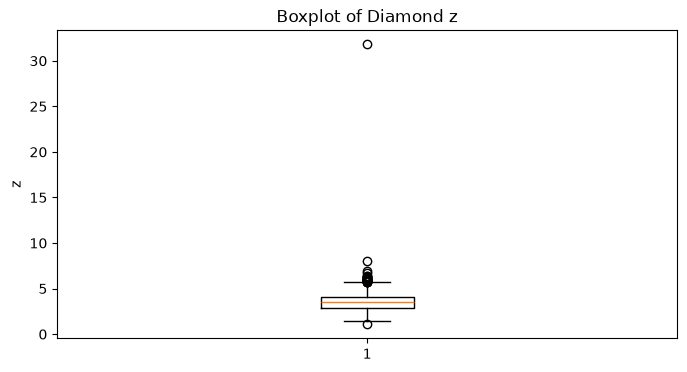

In [39]:
for col in numerical_df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(f"IQR = {IQR} | Q1 = {Q1} | Q3 = {Q3} | lower = {lower} | upper = {upper}")

    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col])
    plt.title(f"Boxplot of Diamond {col}")
    plt.ylabel(col)
    plt.show()


##  relations entre les caractéristiques et le prix 

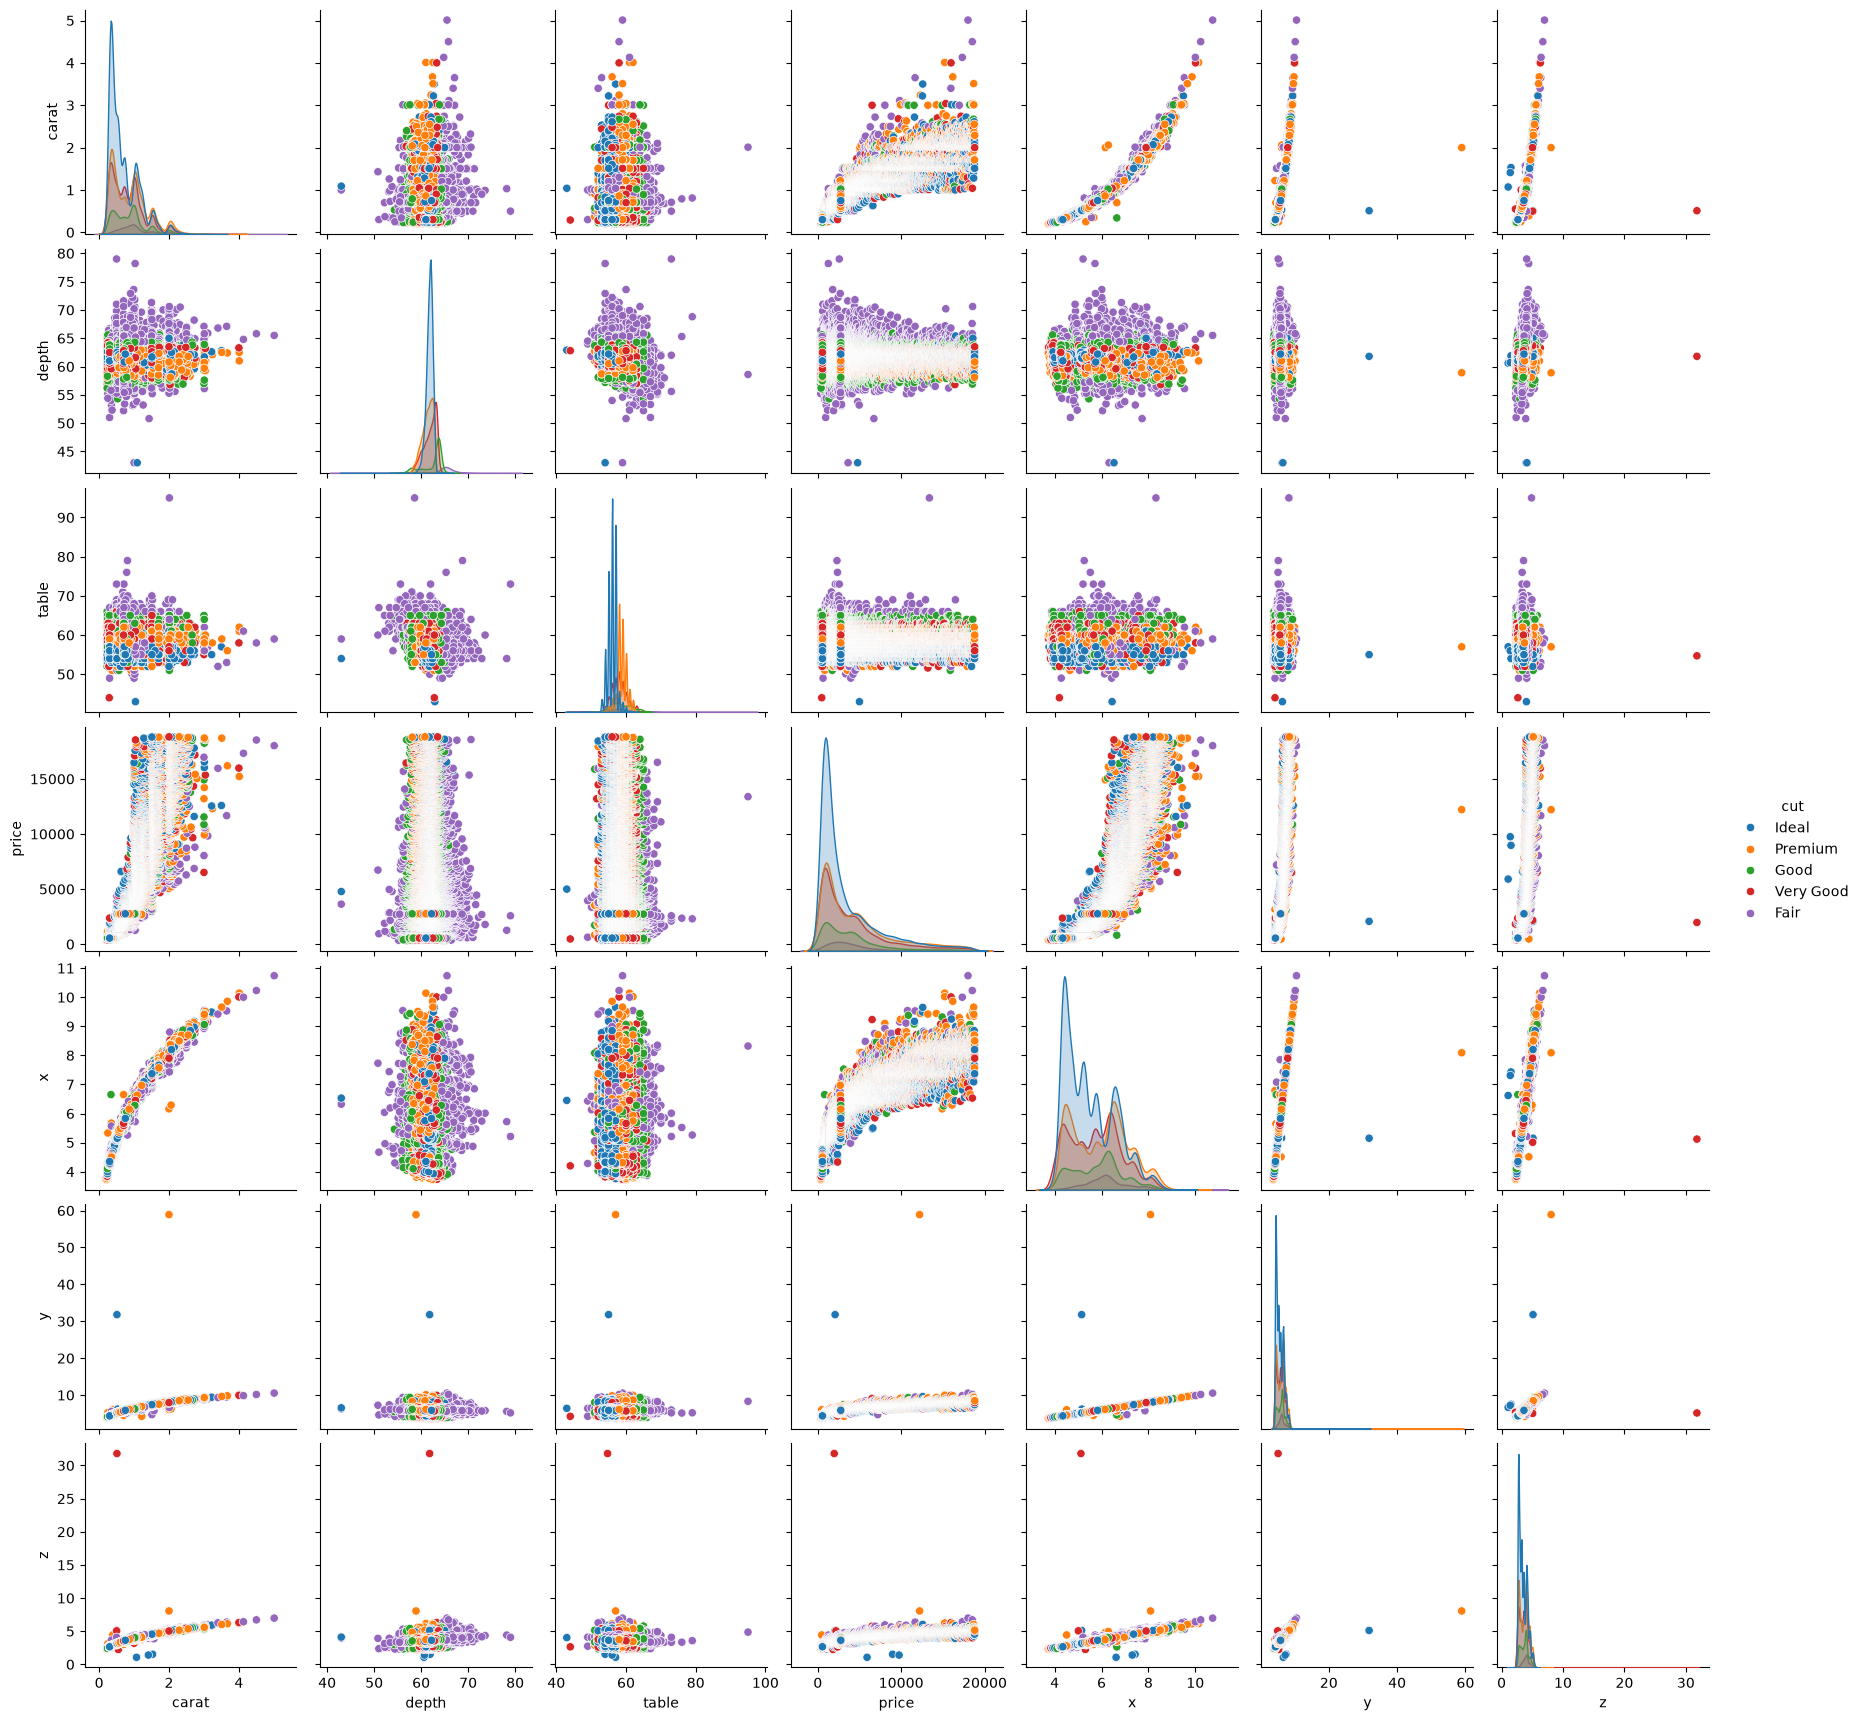

In [40]:
cols = ['carat','depth','table','price','x','y','cut', 'z']

sns.pairplot(
    df[cols],
    hue="cut",
    diag_kind="kde"
)

plt.show()

 ## remove outliers

In [46]:
df = df[
    (df['depth'].between(45, 74)) &
    (df['table'].between(40, 80)) &
    (df['y'] < 20) &
    (df['z'].between(2, 15))
]

df.shape

(49846, 10)

## Correlation Heatmap - What drives the Price?

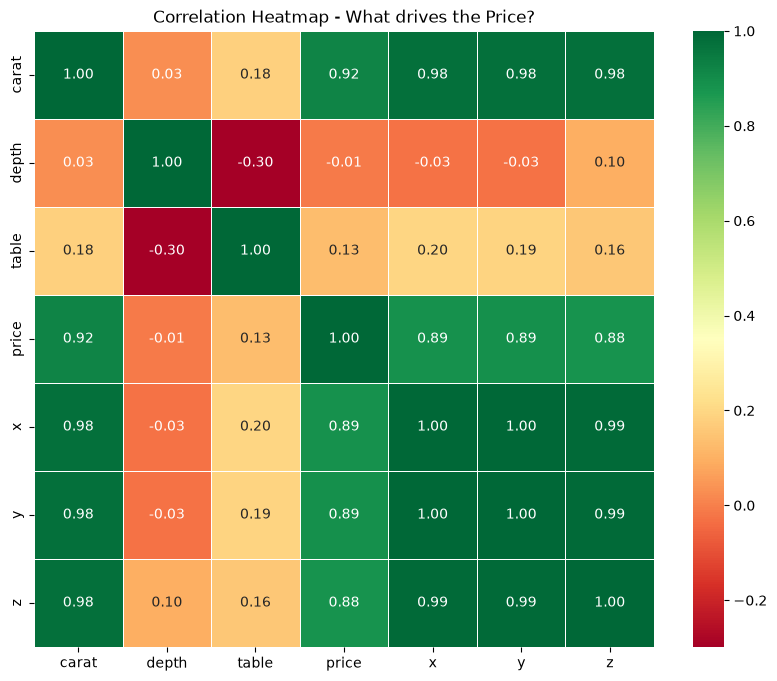

In [50]:
corr_matrix = df[['carat', 'depth', 'table', 'price', 'x', 'y', 'z']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="RdYlGn", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap - What drives the Price?")
plt.show()

## save data cleaned

In [49]:
save_processed(df, "data_cleand.csv")

WindowsPath('C:/Users/lenovo pc/Desktop/diamond-price-ml/data/processed/data_cleand.csv')